# CSCI-4022: Predicting Zebrafish Phenotype from Gene Mutations using Supervised Machine Learning
## Jenn Kaphammer - Spring 2025
### Premise
Zebrafish are commonly used in genetic and ecological research due to their rapid
development. The biologist community utilizes the zebrafish (Danio rerio) as a model
organism to give insight into broader genetic phenomenon. The Zebrafish Information
Network (ZFIN) is an online database that houses publicly available research data on
zebrafish. Utilizing machine learning techniques and models, I am interested in exploring
the phenotypic outcome of zebrafish based on different genetic appearances. How do
gene expressions affect phenotype in zebrafish, and can we accurately predict these
outcomes using a machine learning model? Though the data would allow me to explore severity of phenotype outcomes as well, I am only interested in exploring the binary of if a phenotype shows present in a fish. This allows for more generality of the project and simplicity parsing the data.
#### Hypothesis
Specific mutations identified in the genotype features dataset are significantly associated with abnormal phenotypic outcomes as recorded in the Fish with Abnormal and Normal Phenotypes dataset.
### Sources
https://zfin.org/ : Zebrafish info and datasets (DATASETS USED IN THIS PROJECT UPDATED AS OF 4.6.2025, THERE MAY BE NEWER VERSIONS AVALIABLE) \
https://pandas.pydata.org/docs/index.html: Documentation on properly loading txt files to dataframe/manipulating dfs. I also used the built-in dummy method to save time on one-hot encoding. If I were to one-hot encode from scratch, I would approach it by isolating the unique strings from each qualitative column. I would then manually replace each string with an assigned number throughout the whole dataframe.\
*CSCI-4022 Notebook 4 k-means* : Since it isn't permitted for this project to use a built-in method such as scipy's Kmeans for clustering, I based my implementation on the standards outlined in notebook 4.\
*SKlearn PCA method* : While we discussed PCA in class, we did not go over methods to implement within code. The sklearn built-in decomposition methods allows for me to take my extremely large feature matrix and compress in 2D. If I were to do this manually, I would first make sure each feature has zero mean (centered data). The next step is to compute the covariance matrix, and perform eigen-decomposition. Then top components would be selected and projected in 2D. Upon looking at the documentation, sklearn's method does this all 'under the hood'.\
*Pattern Recognition and Machine Learning by Christopher M. Bishop* : While I learned about logistic regression in intro to data science/stats, it had been a while since I coded it/utilized it. Chapter 4 of this textbook discusses logistic regression methods which I used for my implementation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
from sklearn.decomposition import PCA

## Data Loading
Upon looking at the txt files, the data looks to be using tabs as a deliminator, and there is metadata (date) on the first line of every file. I also want to make sure that data is loaded as a string since the numbers are qualitative to represent gene markers.

In [2]:
#Genotype Features
genotype_df = pd.read_csv('zfin-data/genotype_features_2025.04.06.txt', sep='\t', skiprows=1, header=0, dtype=str)

In [3]:
#Fish with Abnormal and Normal Phenotypes
comparison_phenotype_df = pd.read_csv('zfin-data/phenotype_fish_2025.04.06.txt', sep='\t', skiprows=1, header=0, dtype=str)

In [4]:
#Phenotype of Zebrafish Genes
phenotype_df = pd.read_csv('zfin-data/phenoGeneCleanData_fish_2025.04.06.txt', sep='\t', skiprows=1, header=0, dtype=str)

In [5]:
#check dfs loading
genotype_df.head(3)

,Genotype ID,Genotype Name,Genotye Unique Name,Allele ID,Allele Name,Allele Abbreviation,Allele Type,Allele Display Type,Gene or Construct Symbol,Corresponding ZFIN Gene ID/Construct ID,Allele Zygosity,Construct Name,Construct ZdbId,Unnamed: 13
0,ZDB-GENO-000209-20,enm<sup>w16</sup>,"w16[U,U,U]",ZDB-ALT-000209-24,w16,w16,sequence alteration,Unknown,enm,ZDB-GENE-070117-34,unknown,NaN,NaN,NaN
1,ZDB-GENO-000215-8,Df(Chr03)c1033/c1033,"c1033[2,U,U]AB",ZDB-ALT-000215-12,Df(Chr03)c1033,c1033,deficiency,Deficiency,NaN,NaN,homozygous,NaN,NaN,NaN
2,ZDB-GENO-000405-1,Df(Chr24:reck)w15,"w15[U,U,U]",ZDB-ALT-000405-2,Df(Chr24:reck)w15,w15,deficiency,Deficiency,NaN,NaN,unknown,NaN,NaN,NaN


In [6]:
phenotype_df.head(3)

,ID,Gene Symbol,Gene ID,Affected Structure or Process 1 subterm ID,Affected Structure or Process 1 subterm Name,Post-composed Relationship ID,Post-composed Relationship Name,Affected Structure or Process 1 superterm ID,Affected Structure or Process 1 superterm Name,Phenotype Keyword ID,...,Affected Structure or Process 2 superterm ID,Affected Structure or Process 2 superterm name,Fish ID,Fish Display Name,Start Stage ID,End Stage ID,Fish Environment ID,Publication ID,Figure ID,Unnamed: 25
0,632527863,3m76,ZDB-GENE-210324-7,NaN,NaN,NaN,NaN,ZFA:0000092,axis,PATO:0001592,...,NaN,NaN,ZDB-FISH-210325-47,3m76<sup>stl94/stl94</sup>,ZDB-STAGE-010723-51,ZDB-STAGE-010723-51,ZDB-GENOX-210325-22,ZDB-PUB-201209-13,ZDB-FIG-210325-80,NaN
1,632527862,3m76,ZDB-GENE-210324-7,NaN,NaN,NaN,NaN,ZFA:0001559,vertebral column,PATO:0001592,...,NaN,NaN,ZDB-FISH-210325-47,3m76<sup>stl94/stl94</sup>,ZDB-STAGE-010723-51,ZDB-STAGE-010723-51,ZDB-GENOX-210325-22,ZDB-PUB-201209-13,ZDB-FIG-210325-80,NaN
2,632537152,4m99,ZDB-GENE-210324-8,NaN,NaN,NaN,NaN,ZFA:0001559,vertebral column,PATO:0001592,...,NaN,NaN,ZDB-FISH-210325-48,4m99<sup>stl205/stl205</sup>,ZDB-STAGE-010723-51,ZDB-STAGE-010723-51,ZDB-GENOX-210325-23,ZDB-PUB-201209-13,ZDB-FIG-210325-80,NaN


In [7]:
comparison_phenotype_df.head(3)

,Fish ID,Fish Name,Start Stage ID,Start Stage Name,End Stage ID,End Stage Name,Affected Structure or Process 1 subterm ID,Affected Structure or Process 1 subterm Name,Post-composed Relationship ID,Post-composed Relationship Name,...,Phenotype Tag,Affected Structure or Process 2 subterm ID,Affected Structure or Process 2 subterm name,Post-composed Relationship (rel) ID,Post-composed Relationship (rel) Name,Affected Structure or Process 2 superterm ID,Affected Structure or Process 2 superterm name,Publication ID,Environment ID,Unnamed: 23
0,ZDB-FISH-150901-1,aldh1a2<sup>i26/i26</sup>,ZDB-STAGE-050211-1,Unknown,ZDB-STAGE-050211-1,Unknown,NaN,NaN,NaN,NaN,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-060503-2,ZDB-EXP-041102-1,NaN
1,ZDB-FISH-150901-1,aldh1a2<sup>i26/i26</sup>,ZDB-STAGE-050211-1,Unknown,ZDB-STAGE-050211-1,Unknown,NaN,NaN,NaN,NaN,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-060503-2,ZDB-EXP-041102-1,NaN
2,ZDB-FISH-150901-10,AB/TU + MO1-itga7,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,NaN,NaN,NaN,NaN,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-131119-10,ZDB-EXP-140122-5,NaN


## Data Cleaning
To be able to cluster the data and check genotype/phenotype relations accurately, I now want to combine the info into a numeric matrix. Joining the df tables will allow for clearer k-means clustering.\
First, I want to clean the data by making sure any empty row features (if they exist) are replace with dummy-encoding NA's.

In [8]:
#replace empty spots in dataframe
comparison_phenotype_df = comparison_phenotype_df.replace("", pd.NA)
phenotype_df = phenotype_df.replace("", pd.NA)
genotype_df = genotype_df.replace("", pd.NA)

In [9]:
#it looks like fish names/tags in at least comparison_phenotype_df and genotype_df contain the html tags <sup></sup>,
#I want to get rid of them using regex to make the fish names/ids more clear for processing
genotype_df["Genotype Name"] = (genotype_df["Genotype Name"].str.replace(r"<sup>(.*?)</sup>", r"\1", regex=True))
phenotype_df["Fish Display Name"] = (phenotype_df["Fish Display Name"].str.replace(r"<sup>(.*?)</sup>", r"\1", regex=True))
comparison_phenotype_df["Fish Name"] = (comparison_phenotype_df["Fish Name"].str.replace(r"<sup>(.*?)</sup>", r"\1", regex=True))

In [10]:
#checking if this worked
comparison_phenotype_df.tail(10)

,Fish ID,Fish Name,Start Stage ID,Start Stage Name,End Stage ID,End Stage Name,Affected Structure or Process 1 subterm ID,Affected Structure or Process 1 subterm Name,Post-composed Relationship ID,Post-composed Relationship Name,...,Phenotype Tag,Affected Structure or Process 2 subterm ID,Affected Structure or Process 2 subterm name,Post-composed Relationship (rel) ID,Post-composed Relationship (rel) Name,Affected Structure or Process 2 superterm ID,Affected Structure or Process 2 superterm name,Publication ID,Environment ID,Unnamed: 23
213511,ZDB-FISH-250404-8,i149Tg/i149Tg; i186Tg/i186Tg,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,GO:0097386,glial cell projection,BFO:0000050,part_of,...,normal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-041102-1,NaN
213512,ZDB-FISH-250404-8,i149Tg/i149Tg; i186Tg/i186Tg,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,ZFA:0009077,microglial cell,BFO:0000050,part_of,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-250404-2,NaN
213513,ZDB-FISH-250404-8,i149Tg/i149Tg; i186Tg/i186Tg,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,ZFA:0009077,microglial cell,BFO:0000050,part_of,...,normal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-041102-1,NaN
213514,ZDB-FISH-250404-8,i149Tg/i149Tg; i186Tg/i186Tg,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,ZFA:0009077,microglial cell,BFO:0000050,part_of,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-250404-1,NaN
213515,ZDB-FISH-250404-8,i149Tg/i149Tg; i186Tg/i186Tg,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,ZFA:0009077,microglial cell,BFO:0000050,part_of,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-250404-1,NaN
213516,ZDB-FISH-250404-9,i149Tg/i149Tg; i186Tg/i186Tg + CRISPR1-npc2.1 ...,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,GO:0042995,cell projection,BFO:0000050,part_of,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-041102-1,NaN
213517,ZDB-FISH-250404-9,i149Tg/i149Tg; i186Tg/i186Tg + CRISPR1-npc2.1 ...,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,GO:0045335,phagocytic vesicle,BFO:0000050,part_of,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-041102-1,NaN
213518,ZDB-FISH-250404-9,i149Tg/i149Tg; i186Tg/i186Tg + CRISPR1-npc2.1 ...,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,ZFA:0009077,microglial cell,BFO:0000050,part_of,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-041102-1,NaN
213519,ZDB-FISH-250404-9,i149Tg/i149Tg; i186Tg/i186Tg + CRISPR1-npc2.1 ...,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,ZFA:0009077,microglial cell,BFO:0000050,part_of,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-041102-1,NaN
213520,ZDB-FISH-250404-9,i149Tg/i149Tg; i186Tg/i186Tg + CRISPR1-npc2.1 ...,ZDB-STAGE-010723-35,Larval:Day 4,ZDB-STAGE-010723-35,Larval:Day 4,ZFA:0009077,microglial cell,BFO:0000050,part_of,...,abnormal,NaN,NaN,NaN,NaN,NaN,NaN,ZDB-PUB-241006-5,ZDB-EXP-041102-1,NaN


In [11]:
phenotype_df.head(3)

,ID,Gene Symbol,Gene ID,Affected Structure or Process 1 subterm ID,Affected Structure or Process 1 subterm Name,Post-composed Relationship ID,Post-composed Relationship Name,Affected Structure or Process 1 superterm ID,Affected Structure or Process 1 superterm Name,Phenotype Keyword ID,...,Affected Structure or Process 2 superterm ID,Affected Structure or Process 2 superterm name,Fish ID,Fish Display Name,Start Stage ID,End Stage ID,Fish Environment ID,Publication ID,Figure ID,Unnamed: 25
0,632527863,3m76,ZDB-GENE-210324-7,NaN,NaN,NaN,NaN,ZFA:0000092,axis,PATO:0001592,...,NaN,NaN,ZDB-FISH-210325-47,3m76stl94/stl94,ZDB-STAGE-010723-51,ZDB-STAGE-010723-51,ZDB-GENOX-210325-22,ZDB-PUB-201209-13,ZDB-FIG-210325-80,NaN
1,632527862,3m76,ZDB-GENE-210324-7,NaN,NaN,NaN,NaN,ZFA:0001559,vertebral column,PATO:0001592,...,NaN,NaN,ZDB-FISH-210325-47,3m76stl94/stl94,ZDB-STAGE-010723-51,ZDB-STAGE-010723-51,ZDB-GENOX-210325-22,ZDB-PUB-201209-13,ZDB-FIG-210325-80,NaN
2,632537152,4m99,ZDB-GENE-210324-8,NaN,NaN,NaN,NaN,ZFA:0001559,vertebral column,PATO:0001592,...,NaN,NaN,ZDB-FISH-210325-48,4m99stl205/stl205,ZDB-STAGE-010723-51,ZDB-STAGE-010723-51,ZDB-GENOX-210325-23,ZDB-PUB-201209-13,ZDB-FIG-210325-80,NaN


In [12]:
genotype_df.head(3)

,Genotype ID,Genotype Name,Genotye Unique Name,Allele ID,Allele Name,Allele Abbreviation,Allele Type,Allele Display Type,Gene or Construct Symbol,Corresponding ZFIN Gene ID/Construct ID,Allele Zygosity,Construct Name,Construct ZdbId,Unnamed: 13
0,ZDB-GENO-000209-20,enmw16,"w16[U,U,U]",ZDB-ALT-000209-24,w16,w16,sequence alteration,Unknown,enm,ZDB-GENE-070117-34,unknown,NaN,NaN,NaN
1,ZDB-GENO-000215-8,Df(Chr03)c1033/c1033,"c1033[2,U,U]AB",ZDB-ALT-000215-12,Df(Chr03)c1033,c1033,deficiency,Deficiency,NaN,NaN,homozygous,NaN,NaN,NaN
2,ZDB-GENO-000405-1,Df(Chr24:reck)w15,"w15[U,U,U]",ZDB-ALT-000405-2,Df(Chr24:reck)w15,w15,deficiency,Deficiency,NaN,NaN,unknown,NaN,NaN,NaN


To better fit the outcome I want from my predictive model, I am first going to join tables on the 'fish-level' so each identified fish is it's own datapoint. This will allow for me to see how accurately my model predicts 'fish outcomes'.

**Abormal vs Normal fish phenotypes df**

In [13]:
#make copy of df to keep original intact
comparefishFeatures = comparison_phenotype_df.copy()
#now I one-hot encode the phenotypes so I am able to k-means cluster numerically
#PATO is included in the text data already to mean 'phenotype and trait ontology', so I am including that prefix to know what the 
#one-hot encoded data column represents
#get_dummies automatically matches unique numbers to each phenotype 
comparefishFeatures = pd.get_dummies(comparefishFeatures, columns=["Phenotype Keyword Name"], prefix="PATO")
#encoding qualitative affected structures string
comparefishFeatures = pd.get_dummies(comparefishFeatures, columns=["Affected Structure or Process 1 superterm Name"], dummy_na= True)
comparefishFeatures = pd.get_dummies(comparefishFeatures, columns=["Affected Structure or Process 2 superterm name"], dummy_na= True)


In [14]:
#abnormal vs normal
comparefishFeatures = pd.get_dummies(comparefishFeatures, columns=["Phenotype Tag"])
#part_of, occurs_in, quality
comparefishFeatures = pd.get_dummies(comparefishFeatures, columns=["Post-composed Relationship Name"])

**Genotype df**

In [15]:
#make copy of df to keep original intact
fishGenos = genotype_df.copy()
#similar to above, now I can one-hot encode needed gene-info
#allele types: ex. point_mutation, deficiency
fishGenos = pd.get_dummies(fishGenos, columns=["Allele Type"])
#display name (deficieny vs insertion)
fishGenos = pd.get_dummies(fishGenos, columns=["Allele Display Type"])
#homo/heterozygous vs unknown. I do not care about the difference between homozygous and heterozygous for this project,
#just if it is present vs unknown
fishGenos = pd.get_dummies(fishGenos, columns=["Allele Zygosity"])

**Phenotype df (links genes -> fish)**

In [16]:
#make copy of df to keep original intact
phenoToGeno = phenotype_df.copy()
#since I am linking genes to fish, I'm going to one-hot with a similar method to the first phenotype df
phenoToGeno = pd.get_dummies(phenoToGeno, columns=["Phenotype Keyword Name"], prefix="PATO")
#encoding qualitative affected structures string
phenoToGeno = pd.get_dummies(phenoToGeno, columns=["Affected Structure or Process 1 superterm Name"], dummy_na= True)
phenoToGeno = pd.get_dummies(phenoToGeno, columns=["Affected Structure or Process 2 superterm name"], dummy_na= True)
#abnormal vs normal
phenoToGeno = pd.get_dummies(phenoToGeno, columns=["Phenotype Tag"])
#part_of, occurs_in, quality
phenoToGeno = pd.get_dummies(phenoToGeno, columns=["Post-composed Relationship Name"])

Now that features have been one-hot encoded, I want to make sure that each fish gets its own row instead of one row per annotation.

In [17]:
#collapsing abnormal vs normal fish phenotype df, getting rid of columns that doesn't matter
#raw columns I want to get rid of
oldCols = ["Fish ID","Fish Name","Start Stage ID","Start Stage Name","End Stage ID","End Stage Name"]
#isolate one-hot cols to list
onehotCompare = [col for col in comparefishFeatures.columns if col not in oldCols]

In [18]:
#collapse rows
fishCollapse = (comparefishFeatures.groupby("Fish ID")[onehotCompare].any().astype("uint8"))

In [19]:
#check
fishCollapse.head(3)

,Affected Structure or Process 1 subterm ID,Affected Structure or Process 1 subterm Name,Post-composed Relationship ID,Affected Structure or Process 1 superterm ID,Phenotype Keyword ID,Affected Structure or Process 2 subterm ID,Affected Structure or Process 2 subterm name,Post-composed Relationship (rel) ID,Post-composed Relationship (rel) Name,Affected Structure or Process 2 superterm ID,...,Affected Structure or Process 2 superterm name_whole organism,Affected Structure or Process 2 superterm name_xanthoblast,Affected Structure or Process 2 superterm name_xanthophore,Affected Structure or Process 2 superterm name_yolk,Affected Structure or Process 2 superterm name_yolk syncytial layer,Affected Structure or Process 2 superterm name_nan,Phenotype Tag_abnormal,Phenotype Tag_normal,Post-composed Relationship Name_occurs_in,Post-composed Relationship Name_part_of
Fish ID,,,,,,,,,,,,,,,,,,,,,
ZDB-FISH-150901-1,0,0,0,1,1,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0
ZDB-FISH-150901-10,0,0,0,1,1,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0
ZDB-FISH-150901-100,1,1,1,1,1,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,1


In [20]:
fishCollapse = fishCollapse.reset_index()

I now have a binary matrix of fish. Now I can cluster this matrix using k-means.

### K-means clustering
- Using Euclidean distance
- Initialized with random centriods (picking K data points)
- Centroids are the avg of the assigned points, and is checked every iteration with convergence

Based on nb04_kmeans.ipynb and my completed CSCI4022 Homework 3 from CSCI4022 file resources

In [55]:
#euclidian distance def
def dist(x1, x2):
    return np.sqrt(np.sum((x1-x2)**2))

In [54]:
def my_kmeans(df, k=3, tol=0.05, max_iters=100, seed=None):
    #inputs dataframe, num of clustres, tolerance check on convergance, max allowed iterations, seed for reproducability if wanted
    #returns centroids, clusters, mean err
    
    #preapre df and get shape
    #gets ndarray from df
    X = df.values if hasattr(df, "values") else np.array(df)
    n,d = X.shape
    #if desired set seed
    if seed != None:
        np.random.seed(seed)
    
    #randomly init centroids
    init = np.random.choice(n, size=k, replace=False)
    centroids = X[init].astype(float)
    #init clusters,mean err tracker (good to have just incase I would like to explore)
    clusters = np.zeros(n, dtype=int)
    mean_errors=[]
    
    #loop
    for i in range(max_iters):
        reconstructionError = 0.0
        #assignment/check reconstrction error
        for j, x in enumerate(X):
            dists = [dist(x, cent) for cent in centroids]
            label = int(np.argmin(dists))
            clusters[j] = label
            reconstructionError += dists[label]**2
        meanErr = reconstructionError/n
        #tolerance check
        if mean_errors and abs(mean_errors[-1]-meanErr)<tol:
            print("Converged to tol in ", i, " iterations")
            break
        mean_errors.append(meanErr)
        #update
        #holds newely generated centroids
        tempCents = np.zeros_like(centroids)
        for cent in range(k):
            cluster_points = X[clusters == cent]
            if len(cluster_points)==0:
                # cluster is empty rand reinit centroid from dataset
                tempCents[cent] = X[np.random.randint(n)]
            else:
                # compute new centroid as the mean of the points in the cluster
                tempCents[cent] = cluster_points.mean(axis=0)
        centroids = tempCents
    return centroids, clusters, mean_errors
        

To determine which K is best to use, I am going to make an 'elbow plot' that compares reconstrction error on k's. I want to choose a K where the graph begins to converge, but without converging too far to prevent overfitting.

In [56]:
#loading feature matrix
X_df = fishCollapse.drop(columns=["Fish ID"])
#trying even integers k=1 to k=10
k_list = [2,4,6,8,10]
err_list = []

# quick-method k elbow test since df is large
for k in k_list:
    cents, clust, errs = my_kmeans(X_df, k=k, tol=1e-3, max_iters=50, seed=42)
    err_list.append(errs[-1])   # final avg. error

Converged to tol in  3  iterations
Converged to tol in  9  iterations
Converged to tol in  10  iterations
Converged to tol in  9  iterations
Converged to tol in  11  iterations


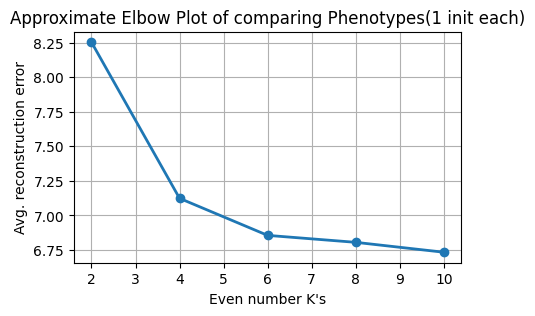

In [45]:
plt.figure(figsize=(5,3))
plt.plot(k_list, err_list, 'o-', lw=2)
plt.xlabel("Even number K's")
plt.ylabel("Avg. reconstruction error")
plt.title("Approximate Elbow Plot of comparing Phenotypes(1 init each)")
plt.grid(True)
plt.show()

Based on this plot, k=6 seems like a good choice. The graph begins to converge but without overfitting. \
I can now perform a final k-means with k=6. Due to the vastness of the dataset, I will be performing a single runthrough of my_kmeans. If this was a funded and more robust research project, I would likely instead loop multiple times. I am also choosing to keep the seed consistent at 42 for reproducability.

In [32]:
final_df = fishCollapse.drop(columns=["Fish ID"])

In [24]:
#run kmeans
centroids, clusters, errors = my_kmeans(final_df, k=6, tol=1e-3, max_iters=100, seed=42)

Converged to tol in  10  iterations


In [30]:
#attach cluster assignment
X_features = final_df.values
fishCollapse["fish_cluster"] = clusters

In [31]:
#PCA in 2d
pcaFishCollapse = PCA(n_components=2, random_state=0)
dim = pcaFishCollapse.fit_transform(X_features)

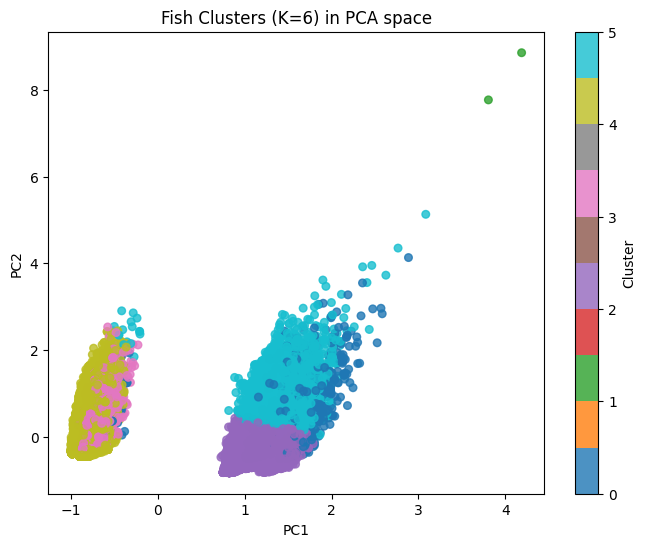

In [34]:
#plotting in 2d based on PCA, coloring with clusters
plt.figure(figsize=(8,6))
scatter = plt.scatter(dim[:,0], dim[:,1],c=clusters, cmap="tab10", s=30, alpha=0.8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Fish Clusters (K=6) in PCA space")
plt.colorbar(scatter, label="Cluster")
plt.show()

This gives me a general view of all genotype features in 2D. Now, I can map fish to genes present within the other dataframes.

In [21]:
#linking fish ID's to genes. genes are labled within gene symbols in the phenotype data frame.
#first collapse phenoToGene and fishGeno to one row per gene, isolating numeric columns
numPhenoToGeno = phenoToGeno.select_dtypes(include=[np.number, "boolean"]).columns.tolist()
#check key for table merging
groupPhenoToGeno = ["Gene Symbol"] + [col for col in numPhenoToGeno if col != "Gene Symbol"]
features_phenoToGeno = (phenoToGeno[groupPhenoToGeno].groupby("Gene Symbol").max().reset_index())

numFishGeno = fishGenos.select_dtypes(include=[np.number, "boolean"]).columns.tolist()
groupFishGeno = ["Gene or Construct Symbol"] + [col for col in numFishGeno if col != "Gene or Construct Symbol"]
features_fishGeno =(fishGenos[groupFishGeno].groupby("Gene or Construct Symbol").max().reset_index())

In [22]:
features_fishGeno = features_fishGeno.rename(columns={"Gene or Construct Symbol": "Gene Symbol"})

In [23]:
#merge geno and pheno features onto eachother, outer join
geneFeatures = features_phenoToGeno.merge(features_fishGeno,on="Gene Symbol",how="outer",suffixes=("_pheno","_geno"))

There's many target variables/features we can try to predict. I'm going to explore if abnormal/normal phenotypes are predictable from gene expression.

### Regression/Predictive Model
This is based off of maximum likelihood estimates to be the base of the model.

In [24]:
#abnormal vs normal phenotypes
#populate empty table
test_df = geneFeatures.fillna(0)
#if abnormal=1, 0=normal
y = test_df["Phenotype Tag_abnormal"].astype(float).values
#drop identifiers that aren't features
xDf = test_df.drop(columns=["Gene Symbol", "Phenotype Tag_abnormal", "Phenotype Tag_normal"],errors="ignore")
x = xDf.values.astype(float)
#add intercept so boundary fits data better
x = np.hstack([np.ones((x.shape[0], 1)), x])
#split into 80/20 train test
n = x.shape[0]
idx = np.random.permutation(n)
split = int(0.8*n)
trainIdx = idx[:split]
testIdx = idx[split:]
x_train, y_train, x_test, y_test = x[trainIdx], y[trainIdx], x[testIdx], y[testIdx]

In [44]:
#logistic regression
#first I need to define sigmoid
def sigmoid(z):
    return 1/(1+np.exp(-z))
#parameters for regression
lr=0.01
tol=1e-3
max_iter=1000
#take super small constant to avoid log(0)
epsilon = 1e-20
prev = float('inf')
weight = np.zeros(x_train.shape[1])

In [41]:
#I want to check the distribution of normal vs. abnormal so weights can be set appropriatly
print("Positive class ratio in train set: ", y_train.mean())

Positive class ratio in train set:  0.8460060389788636


This output suggests that around 85% of the fish are labeled abnormal and 15% normal. This isn't very balanced, so I'm going to try computing weights based on the inverse of the class frequency to balance it out.

In [45]:
# compute class‐weights
n_train = len(y_train)
#abnormal
n_pos = np.sum(y_train)
#normal
n_neg = n_train - n_pos
weight_pos = 1.0/n_pos
weight_neg = 1.0/n_neg

# example weights on vector
sampleWeights = np.where(y_train==1, weight_pos, weight_neg)

# logistic regression with weighted loss/gradient
for i in range(max_iter):
    #use dot product
    z = x_train.dot(weight)
    p = sigmoid(z)
    
    # weighted gradient
    # divide by sum for avg
    gradient = x_train.T.dot(sampleWeights * (p-y_train)) 
    gradient /= sampleWeights.sum()
    weight -= lr*gradient
    
    # weighted cross‐entropy loss
    loss = -(sampleWeights*(y_train*np.log(p+epsilon)+(1-y_train)*np.log(1-p+epsilon))).sum()
    loss /= sampleWeights.sum()
    
    # check convergence
    if abs(prev-loss) < tol:
        print("Converged to tol in ", i, " iterations")
        break
    prev = loss

Converged to tol in  90  iterations


In [46]:
#now I can have the model make predictions on the test set
zTest = x_test.dot(weight)
pTest = sigmoid(zTest)
yPred = (pTest >= 0.5).astype(int)

#manually compute to compare
acc  = np.mean(yPred==y_test)
truePos = np.sum((yPred==1)&(y_test==1))
falsePos = np.sum((yPred==1)&(y_test==0))
falseNeg = np.sum((yPred==0)&(y_test==1))

precision = truePos/(truePos + falsePos) if (truePos + falsePos) >0 else 0.0
recall = truePos/(truePos + falseNeg) if (truePos + falseNeg) > 0 else 0.0

print("Test accuracy: ",  acc)
print("Test precision:", precision)
print("Test recall:   ", recall)


Test accuracy:  0.9840834248079035
Test precision: 0.9836785938480854
Test recall:    0.9980891719745223


In [47]:
#now I can have the model make predictions on the test set
zTest = x_test.dot(weight)
pTest = sigmoid(zTest)
yPred = (pTest >= 0.5).astype(int)

In [48]:
#observe how the predictions compare to reality
#take predicted labels vs true labels, counts match, divide by total
acc = np.mean(yPred==y_test)
#check true positives (abnormal predicted correct), false positive (abnormal predicted incorrect), false negative (normal predicted incorrect)
truePos = np.sum((yPred==1)&(y_test==1))
falsePos = np.sum((yPred==1)&(y_test==0))
falseNeg = np.sum((yPred==0)&(y_test==1))

In [49]:
#precision: how much of flagged positives were true
precision = truePos/(truePos + falsePos) if (truePos + falsePos) >0 else 0.0

In [50]:
#recall: fraction correctly identified abnormal genes
recall = truePos/(truePos + falseNeg) if (truePos + falseNeg) > 0 else 0.0

In [51]:
print("Accuracy: ", acc)
print("Precision: ", precision)
print("Recall: ", recall)

Accuracy:  0.9840834248079035
Precision:  0.9836785938480854
Recall:  0.9980891719745223


In [52]:
#I want to see which of the genotypes relation to the phenotypes. I'm going to turn the weight arr into a series so it will be labeled by feature names
featureName = ["Intercept"] + xDf.columns.tolist()
coeffs = pd.Series(weight, index=featureName)
#10 features with highests weight values (makes abnormal more likely)
print("Top pos weights: ", coeffs.nlargest(10))
#10 features with lowest weight values (makes normal more likely)
print("Top neg weights: ", coeffs.nsmallest(10))

Top pos weights:  Affected Structure or Process 2 superterm name_nan               0.200660
Affected Structure or Process 1 superterm Name_whole organism    0.080241
Post-composed Relationship Name_part_of                          0.077659
PATO_decreased amount                                            0.073850
PATO_disrupted                                                   0.062481
PATO_quality                                                     0.060893
PATO_decreased size                                              0.057193
PATO_morphology                                                  0.045061
Post-composed Relationship Name_occurs_in                        0.040916
PATO_increased amount                                            0.037795
dtype: float64
Top neg weights:  Allele Type_point_mutation                           -0.046549
Allele Display Type_Allele with one point mutation   -0.046549
Allele Zygosity_homozygous                           -0.043675
Intercept           